In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC, LinearSVC
from sklearn.datasets import make_moons

# Load UCI Banknote Authentication Dataset
# Features: 0: variance, 1: skewness, 2: curtosis, 3: entropy | Label: 4: class
data_path = 'data/data_banknote_authentication.txt'
column_names = ['variance', 'skewness', 'curtosis', 'entropy', 'class']

df = pd.read_csv(data_path, header=None, names=column_names)
print(f"Dataset Shape: {df.shape}")
print(df.head())

X_all = df[['variance', 'skewness', 'curtosis', 'entropy']].values
y_all = df['class'].values

# Stratified Split (80% Train, 20% Test)
X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    X_all, y_all, test_size=0.2, random_state=42, stratify=y_all
)

# 2-Feature Subsets (Variance & Skewness) for Part A & B 2D visualizations
X_train_2d = X_train_full[:, :2]
X_test_2d = X_test_full[:, :2]

Dataset Shape: (1372, 5)
   variance  skewness  curtosis  entropy  class
0   3.62160    8.6661   -2.8073 -0.44699      0
1   4.54590    8.1674   -2.4586 -1.46210      0
2   3.86600   -2.6383    1.9242  0.10645      0
3   3.45660    9.5228   -4.0112 -3.59440      0
4   0.32924   -4.4552    4.5718 -0.98880      0


In [2]:
class Node:
    def __init__(self, feature=None, threshold=None, left=None, right=None, *, value=None):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value

    def is_leaf_node(self):
        return self.value is not None

class DecisionTreeScratch:
    def __init__(self, criterion='gini', max_depth=5, min_samples_split=2):
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.root = None

    def _impurity(self, y):
        if len(y) == 0:
            return 0
        p = np.bincount(y) / len(y)
        if self.criterion == 'gini':
            return 1.0 - np.sum(p ** 2)
        elif self.criterion == 'entropy':
            p = p[p > 0]
            return -np.sum(p * np.log2(p))
        else:
            raise ValueError("Criterion must be 'gini' or 'entropy'")

    def _best_split(self, X, y):
        best_gain = -1
        split_idx, split_thresh = None, None
        parent_impurity = self._impurity(y)
        n_features = X.shape[1]

        for feat_idx in range(n_features):
            thresholds = np.unique(X[:, feat_idx])
            for thresh in thresholds:
                left_mask = X[:, feat_idx] <= thresh
                right_mask = ~left_mask

                if np.sum(left_mask) == 0 or np.sum(right_mask) == 0:
                    continue

                y_left, y_right = y[left_mask], y[right_mask]
                n = len(y)
                n_l, n_r = len(y_left), len(y_right)

                gain = parent_impurity - ((n_l / n) * self._impurity(y_left) + (n_r / n) * self._impurity(y_right))

                if gain > best_gain:
                    best_gain = gain
                    split_idx = feat_idx
                    split_thresh = thresh

        return split_idx, split_thresh

    def _build_tree(self, X, y, depth=0):
        n_samples, n_feats = X.shape
        n_labels = len(np.unique(y))

        # Stopping rules
        if (depth >= self.max_depth or n_labels == 1 or n_samples < self.min_samples_split):
            most_common = np.bincount(y).argmax()
            return Node(value=most_common)

        feat_idx, thresh = self._best_split(X, y)

        if feat_idx is None:
            most_common = np.bincount(y).argmax()
            return Node(value=most_common)

        left_mask = X[:, feat_idx] <= thresh
        right_mask = ~left_mask

        left_child = self._build_tree(X[left_mask], y[left_mask], depth + 1)
        right_child = self._build_tree(X[right_mask], y[right_mask], depth + 1)

        return Node(feature=feat_idx, threshold=thresh, left=left_child, right=right_child)

    def fit(self, X, y):
        self.root = self._build_tree(X, y)

    def _predict_sample(self, node, x):
        if node.is_leaf_node():
            return node.value
        if x[node.feature] <= node.threshold:
            return self._predict_sample(node.left, x)
        return self._predict_sample(node.right, x)

    def predict(self, X):
        return np.array([self._predict_sample(self.root, x) for x in X])

    def print_tree(self, node=None, depth=0, feature_names=None):
        if node is None:
            node = self.root
        indent = "  " * depth
        if node.is_leaf_node():
            print(f"{indent}Predict Class: {node.value}")
        else:
            fname = feature_names[node.feature] if feature_names else f"X[{node.feature}]"
            print(f"{indent}[{fname} <= {node.threshold:.4f}]")
            self.print_tree(node.left, depth + 1, feature_names)
            self.print_tree(node.right, depth + 1, feature_names)

# Quick Test on 2D Data
dt_scratch_2d = DecisionTreeScratch(criterion='gini', max_depth=3)
dt_scratch_2d.fit(X_train_2d, y_train_full)
print("--- Learned Manual Tree Split Structure ---")
dt_scratch_2d.print_tree(feature_names=['variance', 'skewness'])

--- Learned Manual Tree Split Structure ---
[variance <= 0.7590]
  [skewness <= 5.1401]
    [variance <= 0.3180]
      Predict Class: 1
      Predict Class: 1
    [variance <= -4.1479]
      Predict Class: 1
      Predict Class: 0
  [variance <= 1.7875]
    [skewness <= 4.8400]
      Predict Class: 0
      Predict Class: 0
    [variance <= 2.3917]
      Predict Class: 0
      Predict Class: 0


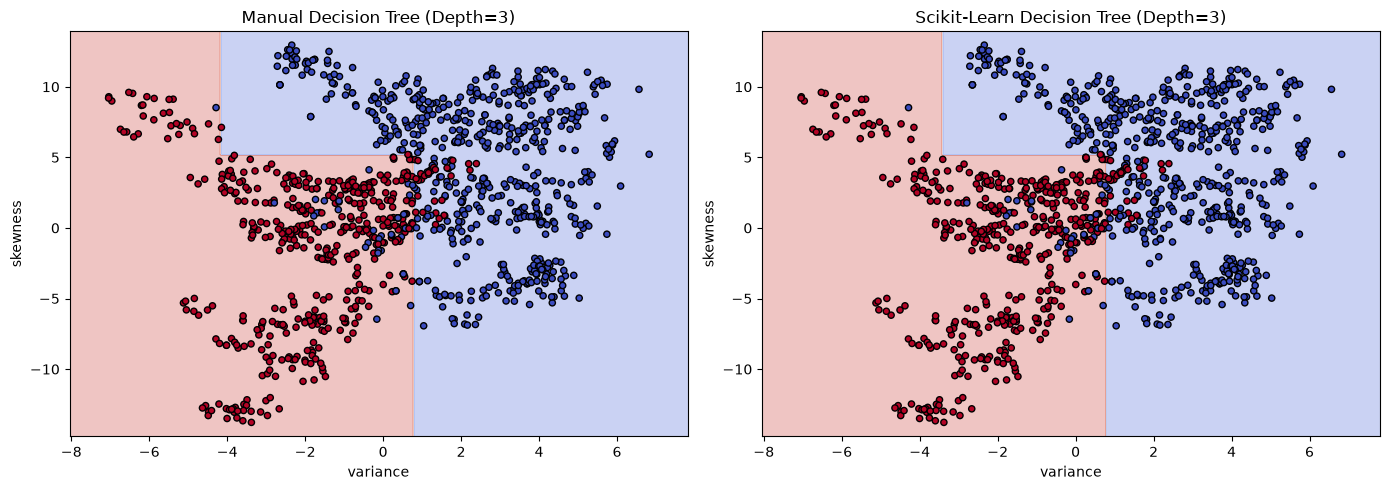

In [3]:
def plot_decision_boundary(model, X, y, title, feature_names=['variance', 'skewness']):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05),
                         np.arange(y_min, y_max, 0.05))

    grid_points = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid_points)
    Z = Z.reshape(xx.shape)

    plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors='k', s=20)
    plt.xlabel(feature_names[0])
    plt.ylabel(feature_names[1])
    plt.title(title)

dt_sk_2d = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
dt_sk_2d.fit(X_train_2d, y_train_full)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plot_decision_boundary(dt_scratch_2d, X_train_2d, y_train_full, "Manual Decision Tree (Depth=3)")

plt.subplot(1, 2, 2)
plot_decision_boundary(dt_sk_2d, X_train_2d, y_train_full, "Scikit-Learn Decision Tree (Depth=3)")
plt.tight_layout()
plt.savefig('decision_tree_boundaries.png')
plt.show()

In [4]:
class StandardScaleScratch:
    def fit_transform(self, X):
        self.mean = np.mean(X, axis=0)
        self.std = np.std(X, axis=0)
        self.std[self.std == 0] = 1.0
        return (X - self.mean) / self.std

    def transform(self, X):
        return (X - self.mean) / self.std

scaler = StandardScaleScratch()
X_train_2d_scaled = scaler.fit_transform(X_train_2d)
X_test_2d_scaled = scaler.transform(X_test_2d)

class LinearSVMScratch:
    def __init__(self, C=1.0, lr=0.001, n_iters=1000):
        self.C = C
        self.lr = lr
        self.n_iters = n_iters
        self.w = None
        self.b = None

    def fit(self, X, y):
        # Map labels to {-1, +1}
        y_svm = np.where(y <= 0, -1, 1)
        n_samples, n_features = X.shape

        self.w = np.zeros(n_features)
        self.b = 0.0

        for _ in range(self.n_iters):
            for idx, x_i in enumerate(X):
                condition = y_svm[idx] * (np.dot(x_i, self.w) + self.b) >= 1
                if condition:
                    dw = self.w
                    db = 0
                else:
                    dw = self.w - self.C * y_svm[idx] * x_i
                    db = -self.C * y_svm[idx]

                self.w -= self.lr * dw
                self.b -= self.lr * db

    def predict(self, X):
        approx = np.dot(X, self.w) + self.b
        return np.where(np.sign(approx) >= 0, 1, 0)

    def decision_function(self, X):
        return np.dot(X, self.w) + self.b

svm_scratch_2d = LinearSVMScratch(C=1.0, lr=0.01, n_iters=2000)
svm_scratch_2d.fit(X_train_2d_scaled, y_train_full)

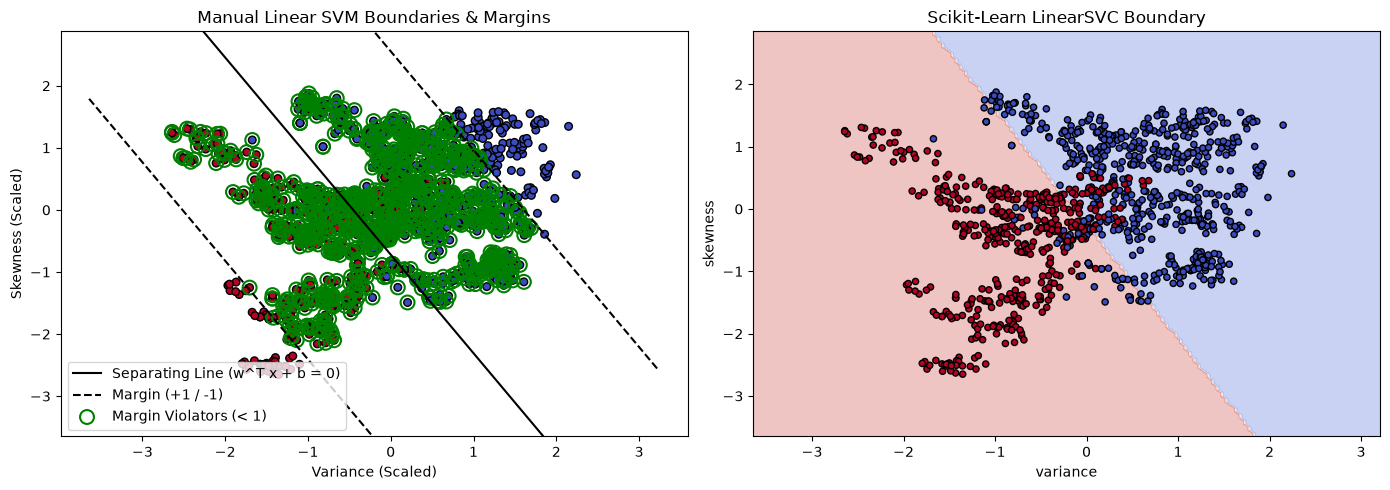

In [6]:
def plot_svm_margins(model, X, y, title):
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors='k', s=30)

    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    xx = np.linspace(x_min, x_max, 200)

    # w0*x + w1*y + b = 0  =>  y = (-w0*x - b) / w1
    w = model.w
    b = model.b

    # Separating hyperplanes
    line_dec = (-w[0] * xx - b) / w[1]
    line_margin_pos = (-w[0] * xx - b + 1) / w[1]
    line_margin_neg = (-w[0] * xx - b - 1) / w[1]

    plt.plot(xx, line_dec, 'k-', label='Separating Line (w^T x + b = 0)')
    plt.plot(xx, line_margin_pos, 'k--', label='Margin (+1 / -1)')
    plt.plot(xx, line_margin_neg, 'k--')

    # Identify margin violators
    y_svm = np.where(y <= 0, -1, 1)
    functional_margins = y_svm * (np.dot(X, w) + b)
    violators = np.where(functional_margins < 1)[0]

    plt.scatter(X[violators, 0], X[violators, 1], facecolors='none',
                edgecolors='g', s=100, linewidths=1.5, label='Margin Violators (< 1)')

    plt.xlabel('Variance (Scaled)')
    plt.ylabel('Skewness (Scaled)')
    plt.ylim(X[:, 1].min() - 1, X[:, 1].max() + 1)
    plt.title(title)
    plt.legend(loc='lower left')

svm_sk_2d = LinearSVC(C=1.0, random_state=42, max_iter=2000)
svm_sk_2d.fit(X_train_2d_scaled, y_train_full)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plot_svm_margins(svm_scratch_2d, X_train_2d_scaled, y_train_full, "Manual Linear SVM Boundaries & Margins")

plt.subplot(1, 2, 2)
plot_decision_boundary(svm_sk_2d, X_train_2d_scaled, y_train_full, "Scikit-Learn LinearSVC Boundary", feature_names=['variance', 'skewness'])
plt.tight_layout()
plt.savefig('svm_boundaries.png')
plt.show()

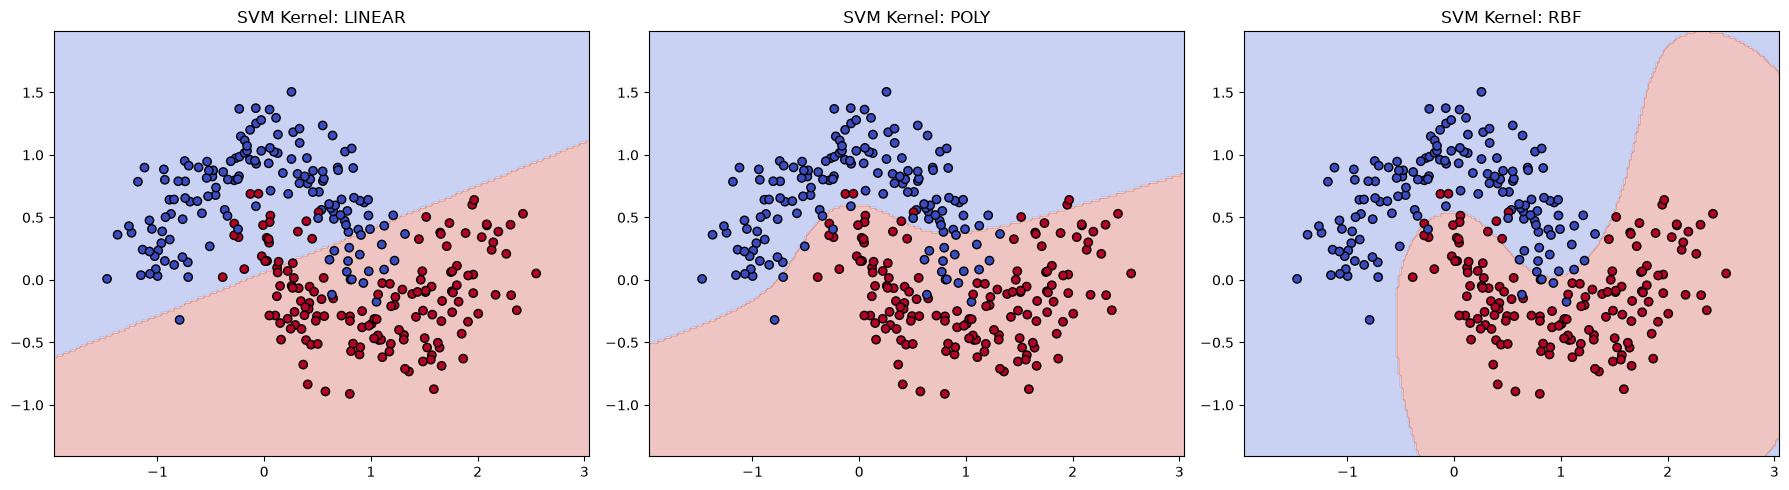

In [7]:
# Generate 2D Nonlinear Moon Dataset
X_moon, y_moon = make_moons(n_samples=300, noise=0.2, random_state=42)

kernels = ['linear', 'poly', 'rbf']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, kernel in enumerate(kernels):
    clf = SVC(kernel=kernel, C=1.0, gamma='scale' if kernel != 'linear' else 'auto')
    clf.fit(X_moon, y_moon)

    plt.subplot(1, 3, idx + 1)
    x_min, x_max = X_moon[:, 0].min() - 0.5, X_moon[:, 0].max() + 0.5
    y_min, y_max = X_moon[:, 1].min() - 0.5, X_moon[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                         np.arange(y_min, y_max, 0.02))

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
    plt.scatter(X_moon[:, 0], X_moon[:, 1], c=y_moon, cmap=plt.cm.coolwarm, edgecolors='k')
    plt.title(f"SVM Kernel: {kernel.upper()}")

plt.tight_layout()
plt.savefig('kernel_svm_comparison.png')
plt.show()

In [8]:
# Standardize full 4-feature dataset for SVM models
scaler_full = StandardScaleScratch()
X_train_full_scaled = scaler_full.fit_transform(X_train_full)
X_test_full_scaled = scaler_full.transform(X_test_full)

models_dict = {
    "Manual Decision Tree": DecisionTreeScratch(criterion='gini', max_depth=5),
    "Scikit-Learn Decision Tree": DecisionTreeClassifier(criterion='gini', max_depth=5, random_state=42),
    "Manual Linear SVM": LinearSVMScratch(C=1.0, lr=0.01, n_iters=2000),
    "Scikit-Learn Linear SVM": LinearSVC(C=1.0, max_iter=2000, random_state=42),
    "Scikit-Learn RBF SVM": SVC(kernel='rbf', C=1.0, random_state=42)
}

results = []

for name, model in models_dict.items():
    # Fit & measure train time
    t0 = time.time()
    if "SVM" in name:
        model.fit(X_train_full_scaled, y_train_full)
    else:
        model.fit(X_train_full, y_train_full)
    train_time = (time.time() - t0) * 1000  # in ms

    # Predict & measure test time
    t1 = time.time()
    if "SVM" in name:
        preds = model.predict(X_test_full_scaled)
    else:
        preds = model.predict(X_test_full)
    pred_time = (time.time() - t1) * 1000  # in ms

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_full, preds),
        "Precision": precision_score(y_test_full, preds),
        "Recall": recall_score(y_test_full, preds),
        "F1-Score": f1_score(y_test_full, preds),
        "Train Time (ms)": round(train_time, 2),
        "Pred Time (ms)": round(pred_time, 2)
    })

comparison_df = pd.DataFrame(results)
print("--- Final Model Performance Comparison (4 Features) ---")
print(comparison_df.to_string(index=False))

--- Final Model Performance Comparison (4 Features) ---
                     Model  Accuracy  Precision   Recall  F1-Score  Train Time (ms)  Pred Time (ms)
      Manual Decision Tree  0.981818   0.983471 0.975410  0.979424           669.69            0.44
Scikit-Learn Decision Tree  0.992727   0.983871 1.000000  0.991870             2.33            0.20
         Manual Linear SVM  0.869091   0.898148 0.795082  0.843478         23965.93            0.04
   Scikit-Learn Linear SVM  0.985455   0.968254 1.000000  0.983871             1.37            0.21
      Scikit-Learn RBF SVM  1.000000   1.000000 1.000000  1.000000             4.87            1.65
